In [1]:
import numpy as np
import pandas as pd

In [2]:
data = pd.read_csv("Dataset\\Cleaned_Marketing_Campaign.csv")
data.head()

,Education,Marital_Status,Income,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,Customer_for,Children,Family_Size,Total_Spending,Total_Accepted_Cmp,Total_Spending_Log,Income_Log,Income_Log_Scaled,Total_Spending_Log_Scaled,Recency_Scaled
0,Graduation,Single,58138.0,58,0.960458,2.50000,2.217593,3.404255,2.50000,1.361702,...,13.02,0,1,1617,1,7.388946,10.970592,0.178462,0.518778,0.585859
1,Graduation,Single,46344.0,38,-0.338189,-0.21875,-0.282407,-0.212766,-0.21875,-0.382979,...,11.52,2,3,27,0,3.332205,10.743869,-0.168676,-0.979110,0.383838
2,Graduation,Partnered,71613.0,26,0.525494,1.28125,0.277778,2.106383,0.40625,0.382979,...,12.06,0,1,776,0,6.655440,11.179046,0.497627,0.247942,0.262626
3,Graduation,Partnered,26646.0,26,-0.338189,-0.12500,-0.217593,-0.042553,-0.15625,-0.404255,...,11.59,1,2,53,0,3.988984,10.190432,-1.016046,-0.736605,0.262626
4,PhD,Partnered,58293.0,94,-0.001041,1.09375,0.236111,0.723404,0.59375,-0.191489,...,11.65,1,2,422,0,6.047372,10.973254,0.182538,0.023423,0.949495


In [3]:
data = data[["Education", "Marital_Status", "Age", "Customer_for", "Family_Size","Income_Log_Scaled", "Total_Spending_Log_Scaled", "Recency_Scaled"]]
data = pd.get_dummies(data, columns = ["Education", "Marital_Status"], drop_first=True)

In [4]:
from sklearn.model_selection import train_test_split

X = data.drop("Total_Spending_Log_Scaled", axis=1)
Y = data["Total_Spending_Log_Scaled"]

In [7]:
Y.value_counts()


Total_Spending_Log_Scaled
-0.787868    19
-1.051742    18
-0.710220    16
-0.803924    15
-0.723176    15
             ..
 0.584267     1
 0.562825     1
-0.403790     1
 0.146911     1
 0.218269     1
Name: count, Length: 1054, dtype: int64

In [8]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)

In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.neighbors import KNeighborsRegressor

In [10]:
models = {
    "linear_regression" : LinearRegression(),
    "ridge" : Ridge(alpha = 1.0),
    "lasso" : Lasso(alpha = 0.01),
    "decision_tree" : DecisionTreeRegressor(random_state = 42),
    "random_forest" : RandomForestRegressor(random_state = 42, n_estimators = 100),
    "gradient_boosting" : GradientBoostingRegressor(random_state = 42),
    "xgboost" : XGBRegressor(random_state = 42, n_estimators = 200),
    "svm" : SVR(kernel="rbf"),
    "knn" : KNeighborsRegressor(n_neighbors=5)
}

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []
for name, model in models.items():
    model.fit(x_train, y_train)
    y_predict = model.predict(x_test)
    
    mae = mean_absolute_error(y_test, y_predict)
    rmse = np.sqrt(mean_squared_error(y_test, y_predict))
    r2score = r2_score(y_test, y_predict)

    results.append([name, mae, rmse, r2score])

results_df = pd.DataFrame(results, columns=["Model", "R² Score", "MAE", "RMSE"])
print(results_df)

               Model  R² Score       MAE      RMSE
0  linear_regression  0.219309  0.277016  0.721338
1              ridge  0.219397  0.277075  0.721220
2              lasso  0.223836  0.280270  0.714754
3      decision_tree  0.234275  0.352809  0.547993
4      random_forest  0.172399  0.239167  0.792285
5  gradient_boosting  0.175208  0.236776  0.796417
6            xgboost  0.182678  0.260133  0.754271
7                svm  0.255359  0.323323  0.620389
8                knn  0.259867  0.338748  0.583303


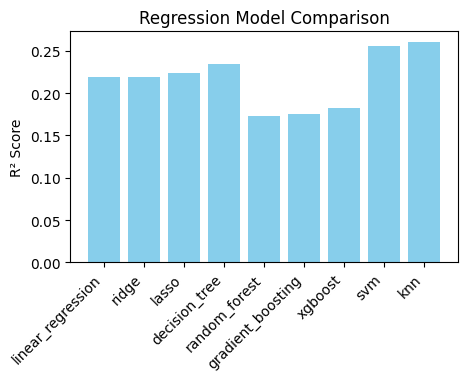

In [17]:
import matplotlib.pyplot as plt
plt.figure(figsize=(5,3))
plt.bar(results_df["Model"], results_df["R² Score"], color="skyblue")
plt.xticks(rotation=45, ha="right")
plt.ylabel("R² Score")
plt.title("Regression Model Comparison")
plt.show()

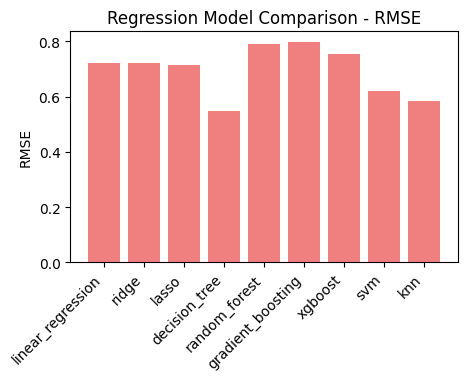

In [18]:
# RMSE plot
plt.figure(figsize=(5,3))
plt.bar(results_df["Model"], results_df["RMSE"], color="lightcoral")
plt.xticks(rotation=45, ha="right")
plt.ylabel("RMSE")
plt.title("Regression Model Comparison - RMSE")
plt.show()

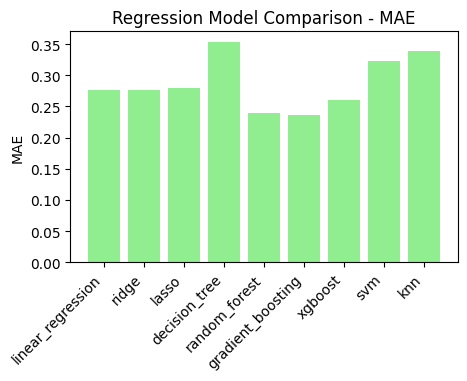

In [19]:
# MAE plot
plt.figure(figsize=(5,3))
plt.bar(results_df["Model"], results_df["MAE"], color="lightgreen")
plt.xticks(rotation=45, ha="right")
plt.ylabel("MAE")
plt.title("Regression Model Comparison - MAE")
plt.show()